# Phase 1: Data Audit, Cleaning, and Integration

This notebook does all of Phase 1 in one place, reading the raw Kaggle CSVs in `data/raw/`. Run it from top to bottom with **Run All**. Each section shows its own code and results, and the last section saves the clean tables as Parquet files in `data/clean/`.

The notebook uses **DuckDB**, which runs SQL directly on CSV and Parquet files and handles the large tables much faster than pandas. Every query result comes back as a pandas DataFrame.

**Sections**
- **Setup:** load the raw CSVs.
- **A. Data audit:** size, types, keys, duplicates, coverage, missing values and joins.
- **B. Player identity and data quality**
- **C. Clean and build the warehouse:** `dim_player`, `dim_team`, `fact_game`, `fact_player_game` and `fact_play`.
- **D. QA:** checks against known NHL records.
- **Save:** write the Parquet files and the reconciliation log.

## Setup

`ANALYSIS_START_SEASON` controls which seasons go into the clean tables. The audit in section A always looks at every season in the raw data.

In [1]:
from pathlib import Path
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 90)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
CLEAN = ROOT / "data" / "clean"
CLEAN.mkdir(parents=True, exist_ok=True)

ANALYSIS_START_SEASON = 2010   # keep seasons 2010-11 and later in the clean tables

con = duckdb.connect()
con.execute("SET TimeZone = 'UTC'")      # keep timestamps in UTC, not your laptop's time zone

def q(sql):
    """Run a SQL query and return a pandas DataFrame."""
    return con.sql(sql).df()

# Reconciliation log: every record we exclude, relabel, or flag gets a row here
LOG = []
def log(entity, entity_id, field, issue, value_found, value_used, resolution, n_records=1):
    LOG.append(dict(entity=entity, entity_id=str(entity_id), field=field, issue=issue,
                    value_found=str(value_found), value_used=str(value_used),
                    resolution=resolution, n_records=n_records))

### Load the raw CSVs

Each CSV is loaded once into DuckDB as `raw_<name>`. The dataset writes missing values as the text `NA`, so that string is read as a true missing value. `birthDate` and `dateTime` are read as text so we can parse them ourselves.

`game_plays.csv` and `game_shifts.csv` are optional: if either is missing, the steps that need it are skipped.

In [2]:
# name -> (candidate key, grain)
SOURCES = {
    "game":               (["game_id"],                                   "one row per game"),
    "team_info":          (["team_id"],                                   "one row per team"),
    "player_info":        (["player_id"],                                 "one row per player"),
    "game_teams_stats":   (["game_id", "team_id"],                        "one row per team per game"),
    "game_skater_stats":  (["game_id", "player_id"],                      "one row per skater per game"),
    "game_goalie_stats":  (["game_id", "player_id"],                      "one row per goalie per game"),
    "game_plays":         (["play_id"],                                   "one row per play/event"),
    "game_plays_players": (["play_id", "player_id", "playerType"],        "one row per player role in a play"),
    "game_goals":         (["play_id"],                                   "one row per goal"),
    "game_penalties":     (["play_id"],                                   "one row per penalty"),
    "game_scratches":     (["game_id", "player_id"],                      "one row per scratched player per game"),
    "game_officials":     (["game_id", "official_name", "official_type"], "one row per official per game"),
    "game_shifts":        (["game_id", "player_id", "period", "shift_start"], "one row per player shift"),
}
TEXT_COLS = {"player_info": ["birthDate"], "game_plays": ["dateTime"]}

loaded = []
for name in SOURCES:
    path = RAW / f"{name}.csv"
    if not path.exists():
        print(f"{name:<20} not found, skipped")
        continue
    header = pd.read_csv(path, nrows=0).columns
    text = {c: "VARCHAR" for c in TEXT_COLS.get(name, []) if c in header}
    types = f", types = {text}" if text else ""
    con.execute(f"""CREATE OR REPLACE TABLE raw_{name} AS
                    SELECT * FROM read_csv('{path.as_posix()}', header = true,
                                           nullstr = 'NA', sample_size = -1{types})""")
    n = con.execute(f"SELECT count(*) FROM raw_{name}").fetchone()[0]
    loaded.append(name)
    print(f"{name:<20} {n:>12,} rows")

for required in ["game", "team_info", "player_info", "game_teams_stats", "game_skater_stats", "game_goalie_stats"]:
    assert required in loaded, f"{required}.csv is missing from {RAW}"
HAS_PLAYS = "game_plays" in loaded

game                       26,305 rows
team_info                      33 rows
player_info                 3,925 rows
game_teams_stats           52,610 rows
game_skater_stats         945,830 rows
game_goalie_stats          56,656 rows
game_plays              5,050,529 rows
game_plays_players      7,586,604 rows
game_goals                148,992 rows
game_penalties            247,828 rows
game_scratches            137,333 rows
game_officials            105,853 rows
game_shifts            11,882,735 rows


# A. Data Audit

### A1. Size and coverage of each table

Row and column counts, plus how many games, players and teams each table covers, and its season range. Season is read from the first four digits of `game_id`: `2016020045` belongs to the season starting in 2016.

In [3]:
def game_id_expr(name):
    cols = [c[0] for c in con.execute(f"DESCRIBE raw_{name}").fetchall()]
    if "game_id" in cols:
        return "CAST(game_id AS BIGINT)", cols
    if "play_id" in cols:                                   # play_id looks like 2016020045_6
        return "CAST(split_part(play_id, '_', 1) AS BIGINT)", cols
    return None, cols

rows = []
for name in loaded:
    gid, cols = game_id_expr(name)
    r = {"table": name, "grain": SOURCES[name][1],
         "rows": con.execute(f"SELECT count(*) FROM raw_{name}").fetchone()[0],
         "columns": len(cols)}
    if gid:
        g = con.execute(f"""SELECT count(DISTINCT {gid}), min(substr(CAST({gid} AS VARCHAR),1,4)),
                                   max(substr(CAST({gid} AS VARCHAR),1,4)) FROM raw_{name}""").fetchone()
        r.update(games=g[0], first_season=f"{g[1]}-{int(g[1])+1-2000:02d}", last_season=f"{g[2]}-{int(g[2])+1-2000:02d}")
    if "player_id" in cols:
        r["players"] = con.execute(f"SELECT count(DISTINCT player_id) FROM raw_{name}").fetchone()[0]
    team_cols = [c for c in cols if c in ("team_id", "home_team_id", "away_team_id")]
    if team_cols:
        union = " UNION ".join(f"SELECT {c} t FROM raw_{name}" for c in team_cols)
        r["teams"] = con.execute(f"SELECT count(DISTINCT t) FROM ({union})").fetchone()[0]
    rows.append(r)
overview = pd.DataFrame(rows)
overview

,table,grain,rows,columns,games,first_season,last_season,teams,players
0,game,one row per game,26305,15,23735.0,2000-01,2019-20,37.0,NaN
1,team_info,one row per team,33,6,NaN,NaN,NaN,33.0,NaN
2,player_info,one row per player,3925,12,NaN,NaN,NaN,NaN,3925.0
3,game_teams_stats,one row per team per game,52610,17,23735.0,2000-01,2019-20,37.0,NaN
4,game_skater_stats,one row per skater per game,945830,22,23721.0,2000-01,2019-20,37.0,3353.0
5,game_goalie_stats,one row per goalie per game,56656,19,23721.0,2000-01,2019-20,37.0,368.0
6,game_plays,one row per play/event,5050529,18,23322.0,2000-01,2019-20,NaN,NaN
7,game_plays_players,one row per player role in a play,7586604,4,23322.0,2000-01,2019-20,NaN,3623.0
8,game_goals,one row per goal,148992,4,23305.0,2000-01,2019-20,NaN,NaN
9,game_penalties,one row per penalty,247828,3,23299.0,2000-01,2019-20,NaN,NaN


### A2. Data types and missing values (data dictionary)

One row per column, showing its data type, the share of missing values, the approximate number of distinct values, and its range. A blank text value (`""`) also counts as missing.

In [4]:
frames = []
for name in loaded:
    prof = q(f"SUMMARIZE raw_{name}")
    n = con.execute(f"SELECT count(*) FROM raw_{name}").fetchone()[0]
    text_cols = prof.loc[prof.column_type == "VARCHAR", "column_name"].tolist()
    blanks = {}
    if text_cols:
        blanks = q("SELECT " + ", ".join(f"count_if(trim({c}) = '') AS \"{c}\"" for c in text_cols)
                   + f" FROM raw_{name}").iloc[0].to_dict()
    frames.append(pd.DataFrame({
        "table": name, "column": prof.column_name, "dtype": prof.column_type,
        "pct_missing": (prof.null_percentage.astype(float)
                        + prof.column_name.map(lambda c: 100 * blanks.get(c, 0) / n)).round(2),
        "approx_distinct": prof.approx_unique, "min": prof["min"], "max": prof["max"]}))
data_dictionary = pd.concat(frames, ignore_index=True)
data_dictionary

,table,column,dtype,pct_missing,approx_distinct,min,max
0,game,game_id,BIGINT,0.00,20551,2000020001,2019040653
1,game,season,BIGINT,0.00,20,20002001,20192020
2,game,type,VARCHAR,0.00,3,A,R
3,game,date_time_GMT,TIMESTAMP WITH TIME ZONE,0.00,15799,2000-10-04 23:00:00+00,2020-09-29 00:00:00+00
4,game,away_team_id,BIGINT,0.00,35,1,90
5,game,home_team_id,BIGINT,0.00,37,1,90
6,game,away_goals,BIGINT,0.00,13,0,11
7,game,home_goals,BIGINT,0.00,13,0,12
8,game,outcome,VARCHAR,0.00,7,away win OT,tbc win tbc
9,game,home_rink_side_start,VARCHAR,4.55,2,left,right


In [5]:
# Only the columns that have missing values
data_dictionary[data_dictionary.pct_missing > 0].sort_values("pct_missing", ascending=False)

,table,column,dtype,pct_missing,approx_distinct,min,max
96,game_plays,secondaryType,VARCHAR,76.60,100,Abuse of Officials,Wrist Shot
118,game_penalties,penaltySeverity,VARCHAR,51.46,6,Bench Minor,Penalty Shot
45,game_teams_stats,faceOffWinPercentage,DOUBLE,42.10,475,0.0,79.2
57,game_skater_stats,hits,BIGINT,42.09,18,0,15
67,game_skater_stats,blocked,BIGINT,42.09,16,0,15
63,game_skater_stats,takeaways,BIGINT,42.09,10,0,8
64,game_skater_stats,giveaways,BIGINT,42.09,10,0,8
28,player_info,birthStateProvince,VARCHAR,28.61,53,AB,WI
97,game_plays,x,BIGINT,22.46,197,-100,100
98,game_plays,y,BIGINT,22.46,74,-42,42


The biggest gaps are in hits, blocks, takeaways, giveaways, faceoff percentage and penalty severity, at about 42% to 51%. The next cell checks whether those gaps are random or depend on the season.

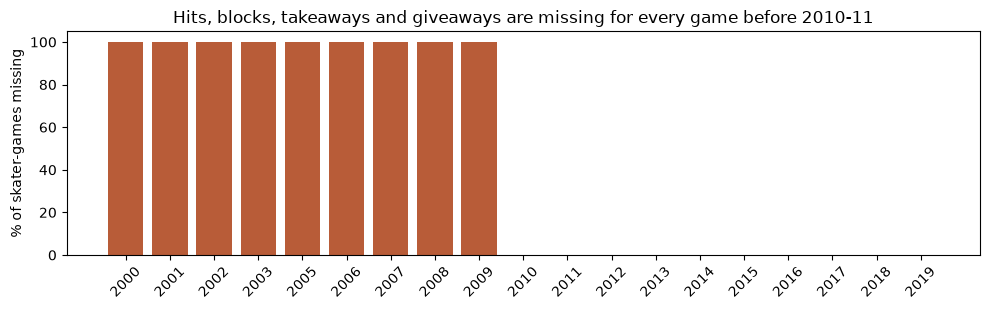

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
season_start,2000,2001,2002,2003,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019
hits,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
blocked,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
takeaways,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
giveaways,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [6]:
miss = q("""
    SELECT substr(CAST(game_id AS VARCHAR), 1, 4) AS season_start,
           round(100 * avg((hits IS NULL)::INT), 1)      AS hits,
           round(100 * avg((blocked IS NULL)::INT), 1)   AS blocked,
           round(100 * avg((takeaways IS NULL)::INT), 1) AS takeaways,
           round(100 * avg((giveaways IS NULL)::INT), 1) AS giveaways
    FROM raw_game_skater_stats GROUP BY 1 ORDER BY 1""")
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(miss.season_start, miss.hits, color=["#b85c38" if v > 50 else "#4a7c9b" for v in miss.hits])
ax.set_ylabel("% of skater-games missing")
ax.set_title("Hits, blocks, takeaways and giveaways are missing for every game before 2010-11")
plt.xticks(rotation=45); plt.tight_layout(); plt.show()
miss.T

The gaps are structural. These stats are missing for every game before 2010-11 and complete from then on, because the NHL didn't record them in this feed for the earlier seasons. That's why the clean tables start at 2010-11 (`ANALYSIS_START_SEASON`).

### A3. Candidate keys and duplicates

Duplicate rows aren't dropped blindly. For each table we compare three counts:

- **rows**: everything in the file.
- **distinct rows**: rows that differ in at least one column.
- **distinct keys**: unique values of the candidate key, such as `game_id + player_id`.

If distinct rows equals distinct keys, every repeated key is an exact copy of another row, so it's a true duplicate and safe to drop. If distinct rows is larger than distinct keys, some keys have two different versions. Those are conflicts that need a rule for choosing between them.

In [7]:
rows = []
for name in loaded:
    key = ", ".join(SOURCES[name][0])
    n, n_distinct, n_keys = con.execute(f"""
        SELECT (SELECT count(*) FROM raw_{name}),
               (SELECT count(*) FROM (SELECT DISTINCT * FROM raw_{name})),
               (SELECT count(*) FROM (SELECT DISTINCT {key} FROM raw_{name}))""").fetchone()
    gid, _ = game_id_expr(name)
    games_dup = None
    if gid and n > n_distinct:
        games_dup = con.execute(f"""SELECT count(DISTINCT g) FROM (SELECT any_value({gid}) g
                        FROM raw_{name} GROUP BY {key} HAVING count(*) > 1)""").fetchone()[0]
    rows.append({"table": name, "candidate_key": key.replace(", ", " + "), "rows": n,
                 "exact_duplicates": n - n_distinct,
                 "pct_duplicates": round(100 * (n - n_distinct) / n, 1),
                 "conflicting_versions": n_distinct - n_keys,
                 "games_with_duplicates": games_dup})
duplicates = pd.DataFrame(rows)
duplicates["verdict"] = duplicates.apply(
    lambda r: "no duplicates" if r.exact_duplicates == 0 and r.conflicting_versions == 0
    else "exact copies only: safe to drop" if r.conflicting_versions == 0
    else "CONFLICTS: needs a tie-break rule", axis=1)
duplicates

,table,candidate_key,rows,exact_duplicates,pct_duplicates,conflicting_versions,games_with_duplicates,verdict
0,game,game_id,26305,2570,9.8,0,2570.0,exact copies only: safe to drop
1,team_info,team_id,33,0,0.0,0,NaN,no duplicates
2,player_info,player_id,3925,0,0.0,0,NaN,no duplicates
3,game_teams_stats,game_id + team_id,52610,5140,9.8,0,2570.0,exact copies only: safe to drop
4,game_skater_stats,game_id + player_id,945830,92426,9.8,0,2570.0,exact copies only: safe to drop
5,game_goalie_stats,game_id + player_id,56656,5493,9.7,0,2570.0,exact copies only: safe to drop
6,game_plays,play_id,5050529,833466,16.5,0,2570.0,exact copies only: safe to drop
7,game_plays_players,play_id + player_id + playerType,7586604,1223800,16.1,0,3365.0,exact copies only: safe to drop
8,game_goals,play_id,148992,15647,10.5,0,2570.0,exact copies only: safe to drop
9,game_penalties,play_id,247828,18600,7.5,0,2562.0,exact copies only: safe to drop


Every table has `conflicting_versions = 0`, so every duplicate is an exact copy. In most tables the copies come from the same 2,570 games, which suggests whole games were loaded twice rather than events being repeated. Here is one of those games:

In [8]:
q("""SELECT * FROM raw_game
     WHERE game_id = (SELECT game_id FROM raw_game GROUP BY 1 HAVING count(*) > 1 ORDER BY 1 LIMIT 1)""")

,game_id,season,type,date_time_GMT,away_team_id,home_team_id,away_goals,home_goals,outcome,home_rink_side_start,venue,venue_link,venue_time_zone_id,venue_time_zone_offset,venue_time_zone_tz
0,2018020001,20182019,R,2018-10-03 23:00:00+00:00,8,10,2,3,home win OT,right,Scotiabank Arena,/api/v1/venues/null,America/Toronto,-4,EDT
1,2018020001,20182019,R,2018-10-03 23:00:00+00:00,8,10,2,3,home win OT,right,Scotiabank Arena,/api/v1/venues/null,America/Toronto,-4,EDT


### A4. Season coverage

The table below shows distinct games per season and game type. The game type comes from digits 5 and 6 of `game_id`: 02 is regular season, 03 is playoffs and 04 is the All-Star Game.

In [9]:
cov = []
for name in loaded:
    gid, _ = game_id_expr(name)
    if gid:
        cov.append(q(f"""SELECT '{name}' AS tbl,
              substr(CAST({gid} AS VARCHAR),1,4) AS season_start,
              CASE substr(CAST({gid} AS VARCHAR),5,2) WHEN '02' THEN 'Regular' WHEN '03' THEN 'Playoff'
                   WHEN '04' THEN 'All-Star' ELSE 'Other' END AS game_type,
              count(DISTINCT {gid}) AS games
            FROM raw_{name} GROUP BY ALL"""))
cov = pd.concat(cov)
cov.pivot_table(index="season_start", columns=["game_type", "tbl"], values="games",
                aggfunc="sum")[["Regular", "Playoff"]].fillna(0).astype(int)

game_type    Regular                                                                                                                                                        Playoff                               \
tbl             game game_goalie_stats game_goals game_officials game_penalties game_plays game_plays_players game_scratches game_shifts game_skater_stats game_teams_stats    game game_goalie_stats game_goals   
season_start                                                                                                                                                                                                       
2000            1230              1230       1199           1217           1205       1206               1206              0           0              1230             1230       0                 0          0   
2001            1230              1230       1194           1223           1196       1196               1196              0           0              1230             1230       0                 0          0   
2002            1230              1230       1193           1230           1196       1196               1196              1           0              1230             1230       0                 0          0   
2003            1230              1230       1204           1211           1209       1209               1209           1226           0              1230             1230       0                 0          0   
2005            1230              1230       1206           1220           1206       1206               1206           1189           0              1230             1230       0                 0          0   
2006            1230              1230       1212           1217           1212       1212               1212           1216           0              1230             1230       0                 0          0   
2007            1230              1230       1207           1146           1207       1207               1207            188           0              1230             1230       0                 0          0   
2008            1230              1230       1211           1226           1211       1211               1211           1228           0              1230             1230       0                 0          0   
2009            1230              1230       1217           1230           1216       1217               1217           1230           0              1230             1230       0                 0          0   
2010            1230              1230       1204           1230           1204       1204               1204           1230        1230              1230             1230      89                89         86   
2011            1230              1230       1207           1230           1206       1207               1207           1230        1230              1230             1230      86                86         86   
2012             720               720        709            720            708        709                709            720         714               720              720      86                86         86   
2013            1230              1230       1209           1230           1206       1209               1209           1230        1216              1230             1230      93                93         92   
2014            1230              1230       1207           1229           1206       1207               1207           1230        1214              1230             1230      89                89         88   
2015            1230              1230       1196           1230           1193       1196               1196           1230        1204              1230             1230      91                91         91   
2016            1230              1230       1216           1230           1213       1216               1216           1230        1213              1230             1230      93     

Regular-season games cover 2000-01 to 2019-20, with no 2004-05 (that season was cancelled by a lockout). Playoff games only start in 2010-11, the same season the hit and block stats begin.

### A5. Join keys and relationship cardinality

Each child table is checked against the parent it joins to:

- **orphans**: child rows whose key has no match in the parent.
- **childless parents**: parent rows with no matching child.
- **children per parent**: the minimum, average and maximum number of child rows for each parent row.

The checks use deduplicated rows.

In [10]:
RELATIONSHIPS = [
    ("game_teams_stats",  "game_id",      "game",        "game_id"),
    ("game_skater_stats", "game_id",      "game",        "game_id"),
    ("game_skater_stats", "player_id",    "player_info", "player_id"),
    ("game_skater_stats", "team_id",      "team_info",   "team_id"),
    ("game_goalie_stats", "game_id",      "game",        "game_id"),
    ("game_goalie_stats", "player_id",    "player_info", "player_id"),
    ("game",              "home_team_id", "team_info",   "team_id"),
    ("game",              "away_team_id", "team_info",   "team_id"),
    ("game_plays",        "game_id",      "game",        "game_id"),
    ("game_plays_players","play_id",      "game_plays",  "play_id"),
    ("game_plays_players","player_id",    "player_info", "player_id"),
    ("game_goals",        "play_id",      "game_plays",  "play_id"),
    ("game_penalties",    "play_id",      "game_plays",  "play_id"),
    ("game_shifts",       "player_id",    "player_info", "player_id"),
]
rows = []
for child, ck, parent, pk in RELATIONSHIPS:
    if child not in loaded or parent not in loaded:
        continue
    r = con.execute(f"""
        WITH c AS (SELECT DISTINCT * FROM raw_{child}), p AS (SELECT DISTINCT {pk} FROM raw_{parent}),
             per AS (SELECT {ck}, count(*) n FROM c GROUP BY 1)
        SELECT (SELECT count(*) FROM c ANTI JOIN p ON c.{ck} = p.{pk}),
               (SELECT count(*) FROM p ANTI JOIN c ON c.{ck} = p.{pk}),
               (SELECT min(n) FROM per), (SELECT round(avg(n), 1) FROM per), (SELECT max(n) FROM per)
    """).fetchone()
    rows.append({"join": f"{child}.{ck} -> {parent}.{pk}", "orphan_child_rows": r[0],
                 "childless_parents": r[1], "children_per_parent_min": r[2],
                 "children_per_parent_avg": r[3], "children_per_parent_max": r[4],
                 "cardinality": "many-to-one" if r[4] > 1 else "one-to-one"})
pd.DataFrame(rows)

,join,orphan_child_rows,childless_parents,children_per_parent_min,children_per_parent_avg,children_per_parent_max,cardinality
0,game_teams_stats.game_id -> game.game_id,0,0,2,2.0,2,many-to-one
1,game_skater_stats.game_id -> game.game_id,0,14,18,36.0,38,many-to-one
2,game_skater_stats.player_id -> player_info.player_id,0,572,1,254.5,1576,many-to-one
3,game_skater_stats.team_id -> team_info.team_id,90,0,18,23065.0,29385,many-to-one
4,game_goalie_stats.game_id -> game.game_id,0,14,1,2.2,4,many-to-one
5,game_goalie_stats.player_id -> player_info.player_id,0,3557,1,139.0,1056,many-to-one
6,game.home_team_id -> team_info.team_id,5,0,1,659.3,821,many-to-one
7,game.away_team_id -> team_info.team_id,5,0,1,659.3,812,many-to-one
8,game_plays.game_id -> game.game_id,0,413,3,180.8,784,many-to-one
9,game_plays_players.play_id -> game_plays.play_id,19,776317,1,1.8,4,many-to-one


Players and games join with no orphans. The only orphans are the 90 skater rows and 5 games tied to team ids 87 to 90, which are All-Star teams that aren't in `team_info`. Some childless parents are expected: for example, most players never appear in the goalie table. The 14 games with no skater stats are explained in section C.

In [11]:
q("""SELECT DISTINCT g.game_id, g.type, g.outcome, g.away_team_id, g.home_team_id
     FROM raw_game g WHERE away_team_id NOT IN (SELECT team_id FROM raw_team_info)""")

,game_id,type,outcome,away_team_id,home_team_id
0,2019040653,A,home win tbc,87,90
1,2018040642,A,away win tbc,88,87
2,2019040652,A,away win tbc,90,89
3,2019040651,A,home win tbc,88,87
4,2018040643,A,away win tbc,88,89


# B. Player Identity and Data Quality

Joins use `player_id`, never a name. The cells below show why, and check the other player fields.

### B1. Do any player ids in the game stats lack a row in `player_info`?

In [12]:
q("""SELECT 'skater stats' src, count(DISTINCT player_id) missing_ids FROM raw_game_skater_stats
       WHERE player_id NOT IN (SELECT player_id FROM raw_player_info)
     UNION ALL
     SELECT 'goalie stats', count(DISTINCT player_id) FROM raw_game_goalie_stats
       WHERE player_id NOT IN (SELECT player_id FROM raw_player_info)""")

,src,missing_ids
0,skater stats,0
1,goalie stats,0


### B2. Players who share a name

These are different people with the same name, so a name-based join would mix up their stats.

In [13]:
same_name = q("""
    SELECT p.firstName || ' ' || p.lastName AS name, p.player_id, p.primaryPosition,
           CAST(substr(p.birthDate, 1, 10) AS DATE) AS birth_date
    FROM raw_player_info p
    QUALIFY count(*) OVER (PARTITION BY p.firstName, p.lastName) > 1
    ORDER BY name, birth_date""")
for name, g in same_name.groupby("name"):
    log("player", name, "name", "two different players share a name",
        " | ".join(f"{r.player_id} ({r.primaryPosition}, b. {r.birth_date})" for r in g.itertuples()),
        "", "kept separate; always join on player_id")
same_name

,name,player_id,primaryPosition,birth_date
0,Alexandre Picard,8470678,D,1985-07-05
1,Alexandre Picard,8471221,LW,1985-10-09
2,Colin White,8465005,D,1977-12-12
3,Colin White,8478400,C,1997-01-30
4,Erik Gustafsson,8475640,D,1988-12-15
5,Erik Gustafsson,8476979,D,1992-03-14
6,Jonas Johansson,8470150,RW,1984-03-18
7,Jonas Johansson,8477992,G,1995-09-19
8,Mike Brown,8466155,LW,1979-04-27
9,Mike Brown,8471371,RW,1985-06-24


### B3. Inconsistent positions

This checks whether any player listed as a goalie appears in the skater stats, or the reverse.

In [14]:
q("""SELECT p.player_id, p.firstName, p.lastName, p.primaryPosition, 'appears as skater' AS conflict
     FROM raw_player_info p WHERE p.primaryPosition = 'G'
       AND p.player_id IN (SELECT player_id FROM raw_game_skater_stats)
     UNION ALL
     SELECT p.player_id, p.firstName, p.lastName, p.primaryPosition, 'appears as goalie'
     FROM raw_player_info p WHERE p.primaryPosition <> 'G'
       AND p.player_id IN (SELECT player_id FROM raw_game_goalie_stats)""")

,player_id,firstName,lastName,primaryPosition,conflict


No conflicts. Every player's listed position matches the stats table they appear in.

### B4. Birth dates

Birth dates are stored as timestamps. Some have a time of `01:00:00` instead of midnight, which is a time-zone conversion artifact. We keep only the date. When a salary dataset is added later, its birth dates can be compared with these, and this dataset should be the trusted source for identity.

In [15]:
bd = q("""SELECT substr(birthDate, 12) AS time_part, count(*) AS players,
                 min(substr(birthDate,1,10)) AS earliest, max(substr(birthDate,1,10)) AS latest,
                 count(*) FILTER (WHERE try_cast(substr(birthDate,1,10) AS DATE) IS NULL) AS unparseable
          FROM raw_player_info GROUP BY 1""")
n_bad_time = int(bd.loc[bd.time_part != "00:00:00", "players"].sum())
log("player", "(all)", "birthDate", "birth date stored with a non-midnight time",
    "YYYY-MM-DD 01:00:00", "YYYY-MM-DD", "kept the calendar date", n_bad_time)
bd

,time_part,players,earliest,latest,unparseable
0,00:00:00,1583,1960-10-24,2001-03-02,0
1,01:00:00,2342,1961-06-01,2001-09-11,0


### B5. Other missing player attributes

In [16]:
pi_missing = q("""SELECT count(*) FILTER (WHERE nationality IS NULL)    AS nationality,
                         count(*) FILTER (WHERE shootsCatches IS NULL)  AS shoots_catches,
                         count(*) FILTER (WHERE height_cm IS NULL)      AS height,
                         count(*) FILTER (WHERE weight IS NULL)         AS weight,
                         count(*) FILTER (WHERE birthCity IS NULL)      AS birth_city
                  FROM raw_player_info""")
for col, n in pi_missing.iloc[0].items():
    if n:
        log("player", "(all)", col, "missing in player_info", "NA", "NULL", "left NULL, not imputed", int(n))
pi_missing

,nationality,shoots_catches,height,weight,birth_city
0,8,17,3,3,5


These gaps are small, so they're left as missing values rather than filled in.

# C. Clean and Build the Warehouse

### C1. Remove exact duplicates

Section A3 showed every duplicate is an exact copy, so `SELECT DISTINCT` removes them without losing information. The deduplicated tables are named `d_<name>`.

In [17]:
for name in loaded:
    if name in ("game_officials", "game_scratches", "game_shifts"):
        continue                                  # audited only, not used in the warehouse
    con.execute(f"CREATE OR REPLACE TABLE d_{name} AS SELECT DISTINCT * FROM raw_{name}")
    before = con.execute(f"SELECT count(*) FROM raw_{name}").fetchone()[0]
    after = con.execute(f"SELECT count(*) FROM d_{name}").fetchone()[0]
    if before != after:
        log(name, "(table)", "(all)", "exact duplicate rows", before, after, "dropped exact copies", before - after)
    print(f"{name:<20} {before:>12,} -> {after:>12,}")

game                       26,305 ->       23,735
team_info                      33 ->           33
player_info                 3,925 ->        3,925
game_teams_stats           52,610 ->       47,470
game_skater_stats         945,830 ->      853,404
game_goalie_stats          56,656 ->       51,163
game_plays              5,050,529 ->    4,217,063
game_plays_players      7,586,604 ->    6,362,804
game_goals                148,992 ->      133,345
game_penalties            247,828 ->      229,228


### C2. Game type: regular season vs playoffs

The raw `type` column (R, P or A) is compared with the game type encoded in `game_id`.

In [18]:
type_check = q("""
    SELECT game_id, season, type AS raw_type,
           CASE substr(CAST(game_id AS VARCHAR),5,2) WHEN '02' THEN 'R' WHEN '03' THEN 'P' WHEN '04' THEN 'A' END AS id_type,
           CAST(date_time_GMT AS DATE) AS game_date, outcome
    FROM d_game WHERE type <> id_type""")
for r in type_check.itertuples():
    log("game", r.game_id, "type", "raw type R but game_id says postseason (Aug 2020 qualifying round)",
        r.raw_type, "Playoff", "used the game_id")
type_check

,game_id,season,raw_type,id_type,game_date,outcome
0,2019030016,20192020,R,P,2020-08-09,away win OT
1,2019030002,20192020,R,P,2020-08-03,home win OT
2,2019030015,20192020,R,P,2020-08-08,away win OT
3,2019030012,20192020,R,P,2020-08-03,home win REG
4,2019030014,20192020,R,P,2020-08-06,away win REG
5,2019030013,20192020,R,P,2020-08-05,away win REG
6,2019030003,20192020,R,P,2020-08-05,away win REG
7,2019030004,20192020,R,P,2020-08-06,home win REG
8,2019030011,20192020,R,P,2020-08-02,home win REG
9,2019030005,20192020,R,P,2020-08-09,home win REG


These 12 games are the August 2020 bubble qualifying round. The NHL counts them as postseason, so the clean tables follow `game_id`.

### C3. Games to exclude, and results to relabel

- **All-Star games** are exhibitions between teams that don't exist in `team_info`.
- **Unplayed games** are "if necessary" playoff games that were scheduled but never played because the series ended early. They have no player stats.
- **Ties**: before 2005 a game could end tied, and those games are coded `tbc win OT`.

In [19]:
q("""SELECT outcome, count(*) AS games,
            count(*) FILTER (WHERE game_id NOT IN (SELECT game_id FROM d_game_skater_stats)) AS without_player_stats,
            min(season) AS first_season, max(season) AS last_season
     FROM d_game GROUP BY 1 ORDER BY 2 DESC""")

,outcome,games,without_player_stats,first_season,last_season
0,home win REG,10157,0,20002001,20192020
1,away win REG,7996,0,20002001,20192020
2,home win OT,2523,0,20002001,20192020
3,away win OT,2412,0,20002001,20192020
4,tbc win OT,628,0,20002001,20032004
5,tbc win tbc,14,14,20162017,20172018
6,away win tbc,3,0,20182019,20192020
7,home win tbc,2,0,20192020,20192020


### C4. Shootouts

The game score gives the shootout winner one extra goal, but the team and player stats don't count it. So when the score total is exactly 1 more than the team-stat goals, the game went to a shootout.

In [20]:
con.execute("""
CREATE OR REPLACE TABLE team_result AS
SELECT h.game_id, h.goals AS home_goals_excl_so, a.goals AS away_goals_excl_so,
       CASE WHEN h.won THEN h.team_id WHEN a.won THEN a.team_id END AS winner_team_id
FROM d_game_teams_stats h JOIN d_game_teams_stats a
  ON h.game_id = a.game_id AND h.HoA = 'home' AND a.HoA = 'away'""")
q("""SELECT substr(CAST(g.game_id AS VARCHAR),5,2) = '03' AS is_playoff, g.outcome,
            (g.home_goals + g.away_goals) - (r.home_goals_excl_so + r.away_goals_excl_so) AS score_minus_stats,
            count(*) AS games
     FROM d_game g JOIN team_result r USING (game_id)
     WHERE g.season >= 20052006 GROUP BY ALL ORDER BY ALL""")

,is_playoff,outcome,score_minus_stats,games
0,False,away win OT,0,1013
1,False,away win OT,1,1049
2,False,away win REG,0,6017
3,False,away win tbc,0,3
4,False,home win OT,0,1092
5,False,home win OT,1,1016
6,False,home win REG,0,7687
7,False,home win tbc,0,2
8,True,away win OT,0,113
9,True,away win OT,1,1


In regular-season OT games after 2005, about half have a difference of 1, which marks a shootout. Two playoff games also have a difference of 1. They're 2020 round-robin seeding games, which used regular-season overtime rules, including shootouts.

### C5. Build `fact_game` (one row per game)

The clean game table:
- Keeps regular-season and playoff games from `ANALYSIS_START_SEASON` onward.
- Takes the game type from `game_id`.
- Converts the start time to the local date at the venue.
- Labels how each game was settled: REG, OT, SO or TIE.

In [21]:
n_before = con.execute(f"""SELECT count(*) FROM d_game WHERE substr(CAST(game_id AS VARCHAR),5,2) IN ('02','03')
                           AND season // 10000 < {ANALYSIS_START_SEASON}""").fetchone()[0]
log("game", f"seasons before {ANALYSIS_START_SEASON}", "season", "outside the analysis window", n_before, 0,
    "excluded: hits/blocks/takeaways/giveaways not recorded before 2010-11", n_before)
for r in q("SELECT game_id FROM d_game WHERE type = 'A'").itertuples():
    log("game", r.game_id, "type", "All-Star exhibition", "A", "", "excluded")
for r in q("""SELECT game_id FROM d_game WHERE outcome = 'tbc win tbc'
              AND game_id NOT IN (SELECT game_id FROM d_game_skater_stats)""").itertuples():
    log("game", r.game_id, "outcome", "scheduled playoff game never played", "tbc win tbc", "", "excluded")

con.execute(f"""
CREATE OR REPLACE TABLE fact_game AS
SELECT
    g.game_id,
    g.season AS season_id,                                                     -- 20162017
    substr(CAST(g.season AS VARCHAR),1,4) || '-' || substr(CAST(g.season AS VARCHAR),7,2) AS season,   -- 2016-17
    CAST(g.season // 10000 AS INT) AS season_start_year,                        -- 2016
    CASE substr(CAST(g.game_id AS VARCHAR),5,2) WHEN '02' THEN 'Regular' ELSE 'Playoff' END AS game_type,
    substr(CAST(g.game_id AS VARCHAR),5,2) = '03' AS is_playoff,
    g.date_time_GMT AS game_start_utc,
    CAST(g.date_time_GMT + to_hours(CAST(g.venue_time_zone_offset AS INT)) AS DATE) AS game_date_local,
    g.home_team_id, g.away_team_id, g.home_goals, g.away_goals,
    r.home_goals_excl_so, r.away_goals_excl_so,
    CASE WHEN g.outcome = 'tbc win OT' THEN 'TIE'
         WHEN (g.home_goals + g.away_goals) - (r.home_goals_excl_so + r.away_goals_excl_so) = 1 THEN 'SO'
         WHEN g.outcome LIKE '%OT' THEN 'OT'
         ELSE 'REG' END AS settled_in,
    CASE WHEN g.home_goals > g.away_goals THEN g.home_team_id
         WHEN g.away_goals > g.home_goals THEN g.away_team_id END AS winner_team_id,
    CASE WHEN g.home_goals > g.away_goals THEN 'Home win'
         WHEN g.away_goals > g.home_goals THEN 'Away win' ELSE 'Tie' END AS result,
    trim(g.venue) AS venue,
    g.venue_time_zone_tz AS venue_time_zone,
    g.outcome AS outcome_raw
FROM d_game g LEFT JOIN team_result r USING (game_id)
WHERE substr(CAST(g.game_id AS VARCHAR),5,2) IN ('02', '03')                 -- drops All-Star games
  AND NOT (g.outcome = 'tbc win tbc' AND g.game_id NOT IN (SELECT game_id FROM d_game_skater_stats))
  AND g.season // 10000 >= {ANALYSIS_START_SEASON}
ORDER BY g.game_id""")
q("""SELECT season, game_type, count(*) AS games,
            count(*) FILTER (WHERE settled_in = 'OT') AS ot, count(*) FILTER (WHERE settled_in = 'SO') AS so
     FROM fact_game GROUP BY ALL ORDER BY ALL""")

,season,game_type,games,ot,so
0,2010-11,Playoff,89,22,0
1,2010-11,Regular,1230,148,149
2,2011-12,Playoff,86,25,0
3,2011-12,Regular,1230,119,181
4,2012-13,Playoff,86,27,0
5,2012-13,Regular,720,65,97
6,2013-14,Playoff,93,26,0
7,2013-14,Regular,1230,129,178
8,2014-15,Playoff,89,19,0
9,2014-15,Regular,1230,136,170


### C6. Build `dim_team` (one row per team)

Two franchises moved during the data period, and each has two team ids: Atlanta became Winnipeg, and Phoenix became Arizona. Both ids are kept, and `franchise_id` links them.

In [22]:
con.execute("""
CREATE OR REPLACE TABLE dim_team AS
SELECT CAST(t.team_id AS INT) AS team_id, trim(t.abbreviation) AS team_abbrev,
       trim(t.shortName) || ' ' || trim(t.teamName) AS team_full_name,
       trim(t.shortName) AS team_location, trim(t.teamName) AS team_name,
       CAST(t.franchiseId AS INT) AS franchise_id,
       min(f.season) AS first_season, max(f.season) AS last_season, count(f.game_id) AS games
FROM d_team_info t
LEFT JOIN (SELECT home_team_id AS team_id, season, game_id FROM fact_game
           UNION ALL SELECT away_team_id, season, game_id FROM fact_game) f USING (team_id)
GROUP BY ALL ORDER BY team_id""")
q("SELECT * FROM dim_team WHERE franchise_id IN (SELECT franchise_id FROM dim_team GROUP BY 1 HAVING count(*) > 1)")

,team_id,team_abbrev,team_full_name,team_location,team_name,franchise_id,first_season,last_season,games
0,11,ATL,Atlanta Thrashers,Atlanta,Thrashers,35,2010-11,2010-11,82
1,27,PHX,Phoenix Coyotes,Phoenix,Coyotes,28,2010-11,2013-14,314
2,52,WPG,Winnipeg Jets,Winnipeg,Jets,35,2011-12,2019-20,724
3,53,ARI,Arizona Coyotes,Arizona,Coyotes,28,2014-15,2019-20,489


### C7. Build `fact_player_game` (one row per player per game)

Skaters and goalies go into one table, with a `player_role` column. Columns are renamed to snake_case. In the goalie table `shots` means shots *against*, so it becomes `shots_against`, which keeps it separate from skater shots. Save percentage is recalculated as a proportion between 0 and 1.

In [23]:
con.execute("""
CREATE OR REPLACE TABLE fact_player_game AS
WITH sk AS (
    SELECT game_id, player_id, team_id, 'Skater' AS player_role,
           timeOnIce AS toi_seconds, evenTimeOnIce AS toi_even_seconds,
           powerPlayTimeOnIce AS toi_pp_seconds, shortHandedTimeOnIce AS toi_sh_seconds,
           goals, assists, goals + assists AS points, shots,
           powerPlayGoals AS pp_goals, powerPlayAssists AS pp_assists,
           shortHandedGoals AS sh_goals, shortHandedAssists AS sh_assists,
           hits, blocked AS blocked_shots, takeaways, giveaways,
           penaltyMinutes AS pim, plusMinus AS plus_minus,
           faceOffWins AS faceoff_wins, faceoffTaken AS faceoffs_taken
    FROM d_game_skater_stats),
gk AS (
    SELECT game_id, player_id, team_id, 'Goalie' AS player_role,
           timeOnIce AS toi_seconds, goals, assists, goals + assists AS points, pim,
           shots AS shots_against, saves,
           evenShotsAgainst AS even_shots_against, evenSaves AS even_saves,
           powerPlayShotsAgainst AS pp_shots_against, powerPlaySaves AS pp_saves,
           shortHandedShotsAgainst AS sh_shots_against, shortHandedSaves AS sh_saves,
           nullif(trim(decision), '') AS goalie_decision
    FROM d_game_goalie_stats),
u AS (SELECT * FROM sk UNION ALL BY NAME SELECT * FROM gk)
SELECT u.game_id, u.player_id, u.team_id,
       CASE WHEN u.team_id = g.home_team_id THEN g.away_team_id ELSE g.home_team_id END AS opponent_team_id,
       u.team_id = g.home_team_id AS is_home,
       g.season, g.game_type, g.game_date_local,
       u.player_role,
       u.toi_seconds, round(u.toi_seconds / 60.0, 2) AS toi_minutes,
       u.* EXCLUDE (game_id, player_id, team_id, player_role, toi_seconds),
       CASE WHEN u.shots_against > 0 THEN round(u.saves / u.shots_against, 4) END AS save_pct,
       u.toi_seconds = 0 AS zero_toi_flag
FROM u JOIN fact_game g USING (game_id)            -- inner join keeps only games in fact_game
ORDER BY u.game_id, u.team_id, u.player_role DESC, u.player_id""")
for r in q("SELECT game_id, player_id FROM fact_player_game WHERE zero_toi_flag").itertuples():
    log("player_game", f"{r.game_id}:{r.player_id}", "timeOnIce", "0 seconds time on ice", 0, 0,
        "kept; flagged zero_toi_flag (leave out of per-60 rates)")
q("""SELECT season, player_role, count(*) AS rows, count(DISTINCT player_id) AS players
     FROM fact_player_game GROUP BY ALL ORDER BY ALL""")

,season,player_role,rows,players
0,2010-11,Goalie,2854,87
1,2010-11,Skater,47466,892
2,2011-12,Goalie,2829,90
3,2011-12,Skater,47371,897
4,2012-13,Goalie,1747,82
5,2012-13,Skater,29014,843
6,2013-14,Goalie,2850,97
7,2013-14,Skater,47623,888
8,2014-15,Goalie,2835,92
9,2014-15,Skater,47478,883


### C8. Build `dim_player` (one row per player)

Standardizing:
- Names are trimmed.
- Birth dates are converted to dates.
- Positions are upper case, with a `position_group` of F, D or G.
- `shares_name_with_another_player` flags the players from B2.

`first_season` and `last_season` come from the analysis window. `career_first_season_in_data` and `career_games_in_data` use the full 2000-01 onward history, so a veteran's experience isn't cut short by the 2010-11 cutoff.

In [24]:
con.execute("""
CREATE OR REPLACE TABLE dim_player AS
WITH p AS (
    SELECT player_id, trim(firstName) AS first_name, trim(lastName) AS last_name,
           trim(firstName) || ' ' || trim(lastName) AS full_name,
           CAST(substr(birthDate, 1, 10) AS DATE) AS birth_date,
           trim(birthCity) AS birth_city, birthStateProvince AS birth_state_province,
           upper(trim(nationality)) AS nationality,
           upper(trim(primaryPosition)) AS primary_position,
           upper(trim(shootsCatches)) AS shoots_catches,
           height_cm, weight AS weight_lb
    FROM d_player_info),
window_games AS (
    SELECT player_id, min(season) AS first_season, max(season) AS last_season,
           count(*) AS games_in_window
    FROM fact_player_game GROUP BY 1),
career AS (
    SELECT x.player_id,
           min(substr(CAST(g.season AS VARCHAR),1,4) || '-' || substr(CAST(g.season AS VARCHAR),7,2)) AS career_first_season_in_data,
           count(*) AS career_games_in_data
    FROM (SELECT game_id, player_id FROM d_game_skater_stats
          UNION SELECT game_id, player_id FROM d_game_goalie_stats) x
    JOIN d_game g USING (game_id)
    WHERE substr(CAST(g.game_id AS VARCHAR),5,2) IN ('02','03')
    GROUP BY 1),
dup AS (SELECT first_name, last_name, count(*) AS n FROM p GROUP BY ALL)
SELECT p.*,
       CASE WHEN primary_position IN ('C','LW','RW') THEN 'F' ELSE primary_position END AS position_group,
       w.first_season, w.last_season, coalesce(w.games_in_window, 0) AS games_in_window,
       c.career_first_season_in_data, coalesce(c.career_games_in_data, 0) AS career_games_in_data,
       dup.n > 1 AS shares_name_with_another_player
FROM p LEFT JOIN window_games w USING (player_id) LEFT JOIN career c USING (player_id)
JOIN dup USING (first_name, last_name)
ORDER BY player_id""")
q("""SELECT full_name, primary_position, position_group, birth_date, first_season,
            career_first_season_in_data, career_games_in_data
     FROM dim_player WHERE full_name IN ('Zdeno Chara', 'Sidney Crosby', 'Connor McDavid', 'Sebastian Aho')""")

,full_name,primary_position,position_group,birth_date,first_season,career_first_season_in_data,career_games_in_data
0,Zdeno Chara,D,D,1977-03-18,2010-11,2000-01,1523
1,Sidney Crosby,C,F,1987-08-07,2010-11,2005-06,1090
2,Connor McDavid,C,F,1997-01-13,2015-16,2015-16,368
3,Sebastian Aho,RW,F,1997-07-26,2016-17,2016-17,333
4,Sebastian Aho,D,D,1996-02-17,2017-18,2017-18,22


### C9. Build `fact_play` (one row per play/event)

This step needs `game_plays.csv`, and is skipped if the file isn't in `data/raw/`. Changes made here:
- Event names get a standard code, such as `BLOCKED_SHOT`.
- Events get a category and shot-attempt flags.
- Goal and penalty details from `game_goals` and `game_penalties` are added.
- `dateTime` is parsed whether it's in Kaggle's format or Excel's format (`10/19/16 1:41`).

In [25]:
if HAS_PLAYS:
    con.execute("""
    CREATE OR REPLACE TABLE fact_play AS
    WITH p AS (SELECT *, upper(regexp_replace(trim(event), '\\s+', '_', 'g')) AS event_code
               FROM d_game_plays)
    SELECT p.play_id, CAST(p.game_id AS BIGINT) AS game_id,
           CAST(split_part(p.play_id, '_', 2) AS INT) AS play_seq,
           g.season, g.game_type,
           trim(p.event) AS event, p.event_code,
           CASE WHEN event_code IN ('SHOT','GOAL','MISSED_SHOT','BLOCKED_SHOT') THEN 'Shot attempt'
                WHEN event_code = 'FACEOFF' THEN 'Faceoff'
                WHEN event_code IN ('GIVEAWAY','TAKEAWAY') THEN 'Possession'
                WHEN event_code = 'HIT' THEN 'Physical'
                WHEN event_code = 'PENALTY' THEN 'Penalty'
                WHEN event_code = 'STOPPAGE' THEN 'Stoppage'
                ELSE 'Game flow / admin' END AS event_category,
           event_code IN ('SHOT','GOAL','MISSED_SHOT','BLOCKED_SHOT') AS is_shot_attempt,
           event_code IN ('SHOT','GOAL') AS is_shot_on_goal,
           nullif(trim(p.secondaryType), '') AS secondary_type,
           CAST(p.team_id_for AS INT) AS team_id_for, CAST(p.team_id_against AS INT) AS team_id_against,
           CAST(p.period AS INT) AS period, upper(trim(p.periodType)) AS period_type,
           upper(trim(p.periodType)) = 'SHOOTOUT' AS is_shootout,
           CAST(p.periodTime AS INT) AS period_time_s,
           try_strptime(p.dateTime, ['%Y-%m-%d %H:%M:%S', '%Y-%m-%dT%H:%M:%SZ', '%m/%d/%y %H:%M', '%m/%d/%Y %H:%M']) AS event_time_utc,
           CAST(p.goals_home AS INT) AS goals_home_after, CAST(p.goals_away AS INT) AS goals_away_after,
           CAST(p.x AS DOUBLE) AS x, CAST(p.y AS DOUBLE) AS y,
           CAST(p.st_x AS DOUBLE) AS st_x, CAST(p.st_y AS DOUBLE) AS st_y,
           gg.strength AS goal_strength, gg.gameWinningGoal AS is_game_winning_goal, gg.emptyNet AS is_empty_net,
           pe.penaltySeverity AS penalty_severity, pe.penaltyMinutes AS penalty_minutes,
           trim(p.description) AS description
    FROM p JOIN fact_game g ON g.game_id = CAST(p.game_id AS BIGINT)
    LEFT JOIN d_game_goals gg USING (play_id)
    LEFT JOIN d_game_penalties pe USING (play_id)
    QUALIFY row_number() OVER (PARTITION BY p.play_id ORDER BY p.dateTime) = 1
    ORDER BY game_id, play_seq""")
    display(q("SELECT event_category, event, count(*) AS plays FROM fact_play GROUP BY ALL ORDER BY 1, 3 DESC"))
else:
    print("game_plays.csv not found in data/raw/, so fact_play is skipped. Add the file and rerun.")

,event_category,event,plays
0,Faceoff,Faceoff,743886
1,Game flow / admin,Period Start,41653
2,Game flow / admin,Period Ready,41604
3,Game flow / admin,Period End,41599
4,Game flow / admin,Period Official,41598
5,Game flow / admin,Game End,12457
6,Game flow / admin,Game Scheduled,12453
7,Game flow / admin,Shootout Complete,1274
8,Game flow / admin,Game Official,1263
9,Game flow / admin,Official Challenge,1028


### C10. Build `bridge_play_player` (one row per player role in a play)

This table links plays to players: who shot, who was the goalie, who scored, who assisted, and so on. The generic label `PlayerID`, used for giveaways and takeaways, is renamed `Primary`.

In [26]:
con.execute("""
CREATE OR REPLACE TABLE bridge_play_player AS
SELECT play_id, CAST(game_id AS BIGINT) AS game_id, player_id,
       CASE playerType WHEN 'PlayerID' THEN 'Primary' ELSE playerType END AS player_role
FROM d_game_plays_players
WHERE CAST(game_id AS BIGINT) IN (SELECT game_id FROM fact_game)""")
q("SELECT player_role, count(*) AS rows FROM bridge_play_player GROUP BY 1 ORDER BY 2 DESC")

,player_role,rows
0,Shooter,1349622
1,Goalie,763816
2,Loser,743886
3,Winner,743886
4,Hitter,587575
5,Hittee,587575
6,Primary,393043
7,Blocker,358843
8,Assist,117034
9,PenaltyOn,101698


# D. QA

### D1. Structural checks

These checks cover unique keys, joins that all find a match, two teams per game, and time-on-ice parts that add up to the total.

In [27]:
checks = {
    "duplicate game_id in fact_game":
        "SELECT count(*) - count(DISTINCT game_id) FROM fact_game",
    "duplicate (game_id, player_id) in fact_player_game":
        "SELECT count(*) - count(DISTINCT (game_id, player_id)) FROM fact_player_game",
    "duplicate player_id in dim_player":
        "SELECT count(*) - count(DISTINCT player_id) FROM dim_player",
    "player rows with no match in dim_player":
        "SELECT count(*) FROM fact_player_game ANTI JOIN dim_player USING (player_id)",
    "player rows with no match in dim_team":
        "SELECT count(*) FROM fact_player_game ANTI JOIN dim_team USING (team_id)",
    "games with no player stats":
        "SELECT count(*) FROM fact_game ANTI JOIN fact_player_game USING (game_id)",
    "games without exactly 2 teams":
        "SELECT count(*) FROM (SELECT game_id FROM fact_player_game GROUP BY 1 HAVING count(DISTINCT team_id) <> 2)",
    "team-games with no goalie":
        "SELECT count(*) FROM (SELECT game_id, team_id FROM fact_player_game GROUP BY ALL HAVING count(*) FILTER (WHERE player_role = 'Goalie') = 0)",
    "skater rows where TOI <> even + PP + SH":
        "SELECT count(*) FROM fact_player_game WHERE player_role = 'Skater' AND toi_seconds <> toi_even_seconds + toi_pp_seconds + toi_sh_seconds",
    "team-games where player goals <> team goals":
        """WITH pg AS (SELECT game_id, team_id, sum(goals) g FROM fact_player_game GROUP BY ALL),
                tg AS (SELECT game_id, home_team_id team_id, home_goals_excl_so goals FROM fact_game
                       UNION ALL SELECT game_id, away_team_id, away_goals_excl_so FROM fact_game)
           SELECT count(*) FROM tg JOIN pg USING (game_id, team_id) WHERE tg.goals <> pg.g""",
    "player-games with zero TOI (flagged)":
        "SELECT count(*) FROM fact_player_game WHERE zero_toi_flag",
}
qa = pd.DataFrame([{"check": k, "count": con.execute(v).fetchone()[0]} for k, v in checks.items()])
qa["status"] = qa["count"].map(lambda n: "PASS" if n == 0 else "CHECK")
qa

,check,count,status
0,duplicate game_id in fact_game,0,PASS
1,"duplicate (game_id, player_id) in fact_player_game",0,PASS
2,duplicate player_id in dim_player,0,PASS
3,player rows with no match in dim_player,0,PASS
4,player rows with no match in dim_team,0,PASS
5,games with no player stats,0,PASS
6,games without exactly 2 teams,0,PASS
7,team-games with no goalie,0,PASS
8,skater rows where TOI <> even + PP + SH,0,PASS
9,team-games where player goals <> team goals,1,CHECK


The few `CHECK` rows are small gaps in the source data, not errors from the cleaning. The next cell lists the goal mismatch.

In [28]:
q("""WITH pg AS (SELECT game_id, team_id, sum(goals) g FROM fact_player_game GROUP BY ALL),
          tg AS (SELECT game_id, home_team_id team_id, home_goals_excl_so goals FROM fact_game
                 UNION ALL SELECT game_id, away_team_id, away_goals_excl_so FROM fact_game)
     SELECT tg.game_id, tg.team_id, tg.goals AS team_goals, pg.g AS player_goals
     FROM tg JOIN pg USING (game_id, team_id) WHERE tg.goals <> pg.g""")

,game_id,team_id,team_goals,player_goals
0,2013020971,29,3,2.0


### D2. Regular-season game counts vs the NHL schedule

Normal seasons have 1,230 games (30 teams). The exceptions are 2012-13, a 48-game lockout season with 720 games; 1,271 games from 2017-18, when Vegas joined; and 2019-20, which stopped at 1,082 games because of COVID-19.

In [29]:
expected = {"2010-11": 1230, "2011-12": 1230, "2012-13": 720, "2013-14": 1230, "2014-15": 1230,
            "2015-16": 1230, "2016-17": 1230, "2017-18": 1271, "2018-19": 1271, "2019-20": 1082}
games = q("SELECT season, count(*) AS actual FROM fact_game WHERE game_type = 'Regular' GROUP BY 1 ORDER BY 1")
games["expected"] = games.season.map(expected)
games["match"] = games.actual == games.expected
games

,season,actual,expected,match
0,2010-11,1230,1230,True
1,2011-12,1230,1230,True
2,2012-13,720,720,True
3,2013-14,1230,1230,True
4,2014-15,1230,1230,True
5,2015-16,1230,1230,True
6,2016-17,1230,1230,True
7,2017-18,1271,1271,True
8,2018-19,1271,1271,True
9,2019-20,1082,1082,True


### D3. Known player seasons

These are official 2016-17 regular-season totals from NHL.com for eight well-known players, compared with what the clean tables give.

In [30]:
known = pd.DataFrame([
    (8478402, "Connor McDavid",  82, 30, 70), (8471675, "Sidney Crosby",   75, 44, 45),
    (8479318, "Auston Matthews", 82, 40, 29), (8479339, "Patrik Laine",    73, 36, 28),
    (8476453, "Nikita Kucherov", 74, 40, 45), (8470613, "Brent Burns",     82, 29, 47),
    (8474578, "Erik Karlsson",   77, 17, 54), (8471214, "Alex Ovechkin",   82, 33, 36),
], columns=["player_id", "player", "official_gp", "official_goals", "official_assists"])
con.register("known", known)
sample = q("""
    SELECT k.player, k.official_gp, count(*) AS our_gp,
           k.official_goals, sum(f.goals) AS our_goals,
           k.official_assists, sum(f.assists) AS our_assists,
           round(avg(f.toi_minutes), 2) AS our_avg_toi_min
    FROM known k JOIN fact_player_game f USING (player_id)
    WHERE f.season = '2016-17' AND f.game_type = 'Regular'
    GROUP BY ALL ORDER BY k.player""")
sample["match"] = ((sample.official_gp == sample.our_gp) & (sample.official_goals == sample.our_goals)
                   & (sample.official_assists == sample.our_assists))
sample

,player,official_gp,our_gp,official_goals,our_goals,official_assists,our_assists,our_avg_toi_min,match
0,Alex Ovechkin,82,82,33,33.0,36,36.0,18.37,True
1,Auston Matthews,82,82,40,40.0,29,29.0,17.63,True
2,Brent Burns,82,82,29,29.0,47,47.0,24.86,True
3,Connor McDavid,82,82,30,30.0,70,70.0,21.13,True
4,Erik Karlsson,77,77,17,17.0,54,54.0,26.84,True
5,Nikita Kucherov,74,74,40,40.0,45,45.0,19.44,True
6,Patrik Laine,73,73,36,36.0,28,28.0,17.91,True
7,Sidney Crosby,75,75,44,44.0,45,45.0,19.88,True


# Save the clean tables

Each warehouse table is written to `data/clean/` as a Parquet file. The reconciliation log, which lists every record that was excluded, relabeled or flagged, is saved alongside them.

In [31]:
tables = ["dim_player", "dim_team", "fact_game", "fact_player_game", "bridge_play_player"]
if HAS_PLAYS:
    tables.append("fact_play")
summary = []
for t in tables:
    path = CLEAN / f"{t}.parquet"
    con.execute(f"COPY {t} TO '{path.as_posix()}' (FORMAT parquet)")
    summary.append({"table": t, "rows": con.execute(f"SELECT count(*) FROM {t}").fetchone()[0],
                    "file": path.name, "size_mb": round(path.stat().st_size / 1e6, 1)})
reconciliation_log = pd.DataFrame(LOG)
reconciliation_log.to_csv(CLEAN / "reconciliation_log.csv", index=False)
pd.DataFrame(summary)

,table,rows,file,size_mb
0,dim_player,3925,dim_player.parquet,0.2
1,dim_team,33,dim_team.parquet,0.0
2,fact_game,12646,fact_game.parquet,0.2
3,fact_player_game,482436,fact_player_game.parquet,7.0
4,bridge_play_player,5914436,bridge_play_player.parquet,54.2
5,fact_play,4023532,fact_play.parquet,117.6


In [32]:
# Summary of the reconciliation log (full detail is in data/clean/reconciliation_log.csv)
reconciliation_log.groupby(["entity", "issue", "resolution"], as_index=False).n_records.sum()

,entity,issue,resolution,n_records
0,game,All-Star exhibition,excluded,5
1,game,exact duplicate rows,dropped exact copies,2570
2,game,outside the analysis window,excluded: hits/blocks/takeaways/giveaways not recorded before 2010-11,11070
3,game,raw type R but game_id says postseason (Aug 2020 qualifying round),used the game_id,12
4,game,scheduled playoff game never played,excluded,14
5,game_goalie_stats,exact duplicate rows,dropped exact copies,5493
6,game_goals,exact duplicate rows,dropped exact copies,15647
7,game_penalties,exact duplicate rows,dropped exact copies,18600
8,game_plays,exact duplicate rows,dropped exact copies,833466
9,game_plays_players,exact duplicate rows,dropped exact copies,1223800


### Using the clean tables later

In a new notebook, you can read them directly:

```python
import duckdb
duckdb.sql("SELECT * FROM 'data/clean/fact_player_game.parquet' LIMIT 5").df()
```

**Decisions carried into the next phase:**
- Join on ids, never names.
- Use the `career_` columns in `dim_player` for experience.
- Compare seasons with per-game or per-60 rates. The 2012-13 and 2019-20 seasons were shortened, so their totals are low.